# 02 · Exploratory Data Analysis
## Kenyan Sign Language (KSL) Recognition with Deep Learning

| | |
|---|---|
| **Course** | DSA 4050-XA: Deep Learning, USIU-Africa (Fall 2026) |
| **Student** | Selmah Tzindori (669602) |
| **Notebook** | `02_eda.ipynb` |
| **Term paper part** | (b) Mine the appropriate dataset (present to the class) |

### Objective
Understand the 6,249 labelled KSL images before modelling: how the classes and orientations are distributed, how image quality varies, whether near-duplicate images exist (a risk of **data leakage** between train and test sets), and what each sign looks like on average. These findings drive the preprocessing and data-split decisions in later notebooks and supply the figures for the dataset presentation.

### Inputs
- `data/raw/kslc_dataset.zip` (restored to local disk)
- `data/processed/catalogue_labelled.csv` (from notebook 01)

### Outputs
| File | Location | Purpose |
|---|---|---|
| `catalogue_eda.csv` | `data/processed/` | Catalogue + orientation, brightness, contrast, sharpness, duplicate group |
| `02_*.png` | `outputs/figures/` | Charts for the report and presentation |
| `02_*.csv` | `outputs/tables/` | Summary tables |
| Key numbers | `outputs/results.json` | Orientation shares, quality stats, duplicate counts |

## 0 · Setup

In [1]:
# =============================================================================
# STANDARD SETUP CELL
# =============================================================================
# 1. Connect Google Drive (where the data, models and outputs live)
from google.colab import drive
drive.mount("/content/drive")

# 2. Make the shared helper file (ksl_utils.py) importable
import sys
sys.path.insert(0, "/content/drive/MyDrive/DSA4050/ksl-recognition/src")

# 3. Import helpers and fix the random seed for reproducibility
import importlib
import ksl_utils as ku
importlib.reload(ku)
ku.set_seed()

# 4. Name of THIS notebook: every saved figure/table/result is tagged with it
NOTEBOOK = "02_eda"

# 5. Shortcuts to the project folders
PATHS = ku.PATHS
print("Project root:", ku.PROJECT_ROOT)

Mounted at /content/drive
Random seed set to 42
Project root: /content/drive/MyDrive/DSA4050/ksl-recognition


In [2]:
# Libraries used in this notebook
import os
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2                                   # OpenCV: image-quality measures
from PIL import Image
from tqdm.auto import tqdm
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# One consistent look for every chart in the project
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
SIGN_COLOUR = "#2E7D6B"                      # main bar colour

In [3]:
# Restore the images to local disk and load the catalogue from notebook 01
DATA_DIR = Path(ku.restore_raw_data())
catalogue = pd.read_csv(os.path.join(PATHS["processed"], "catalogue_labelled.csv"))
df = catalogue[catalogue["readable"]].reset_index(drop=True)   # usable images only
df["abs_path"] = df["rel_path"].apply(lambda p: str(DATA_DIR / p))

SIGNS = sorted(df["label"].unique())
print(f"{len(df)} usable images, {len(SIGNS)} signs")
df.head(3)

Data restored to /content/ksl_data in 46s
6249 usable images, 9 signs


,image_id,label,rel_path,readable,width,height,mode,file_kb,abs_path
0,ImageID_33HMDMJ3,Temple,Images/Images/ImageID_33HMDMJ3.jpg,True,720,1280,RGB,124.8,/content/ksl_data/Images/Images/ImageID_33HMDM...
1,ImageID_V5POEX4O,Church,Images/Images/ImageID_V5POEX4O.jpg,True,720,1280,RGB,84.7,/content/ksl_data/Images/Images/ImageID_V5POEX...
2,ImageID_89CCCCW6,Enough/Satisfied,Images/Images/ImageID_89CCCCW6.jpg,True,1280,720,RGB,119.3,/content/ksl_data/Images/Images/ImageID_89CCCC...


## 1 · Class distribution
Notebook 01 showed the classes are balanced; this chart is the presentation version of that table.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/02_class_distribution.png


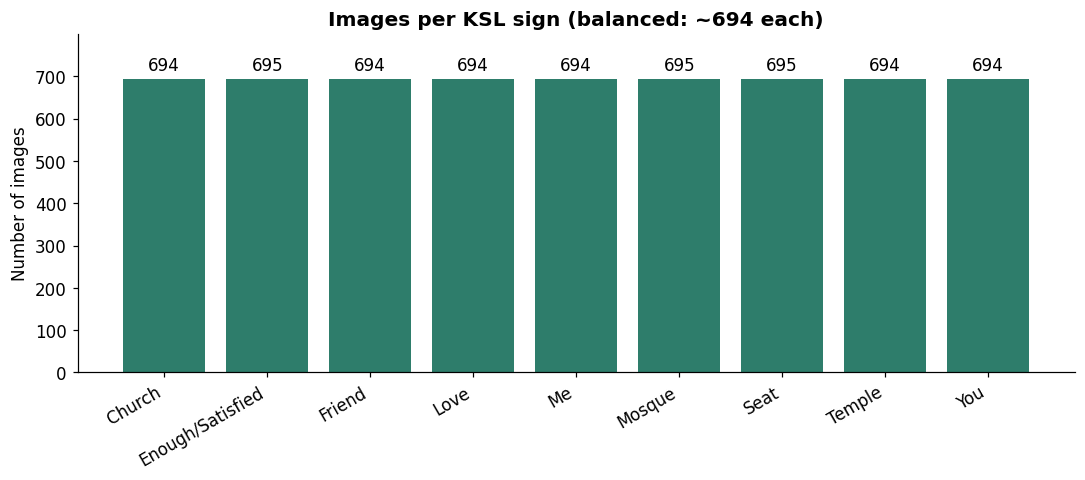

In [4]:
counts = df["label"].value_counts().reindex(SIGNS)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(counts.index, counts.values, color=SIGN_COLOUR)
ax.bar_label(bars, padding=3)                       # show the count on each bar
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Number of images")
ax.set_title("Images per KSL sign (balanced: ~694 each)")
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
ku.save_figure(fig, "02_class_distribution", NOTEBOOK, caption="Number of labelled images per KSL sign.")
plt.show()

**Interpretation:** each sign has 694–695 images (11.1% each), so a model guessing at random would score about **11.1%**. That is the baseline every model must beat.

In [5]:
# Log the random-guess baseline for the report
ku.log_result("random_baseline_accuracy", round(1 / len(SIGNS), 4), NOTEBOOK)

Result logged: random_baseline_accuracy = 0.1111


## 2 · Orientation by sign
Images are either **portrait** (720×1280) or **landscape** (1280×720). If one sign were mostly landscape, a model could learn to "cheat" by recognising the image shape instead of the hand shape. We check whether orientation is spread evenly across signs.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/02_orientation_by_sign.png


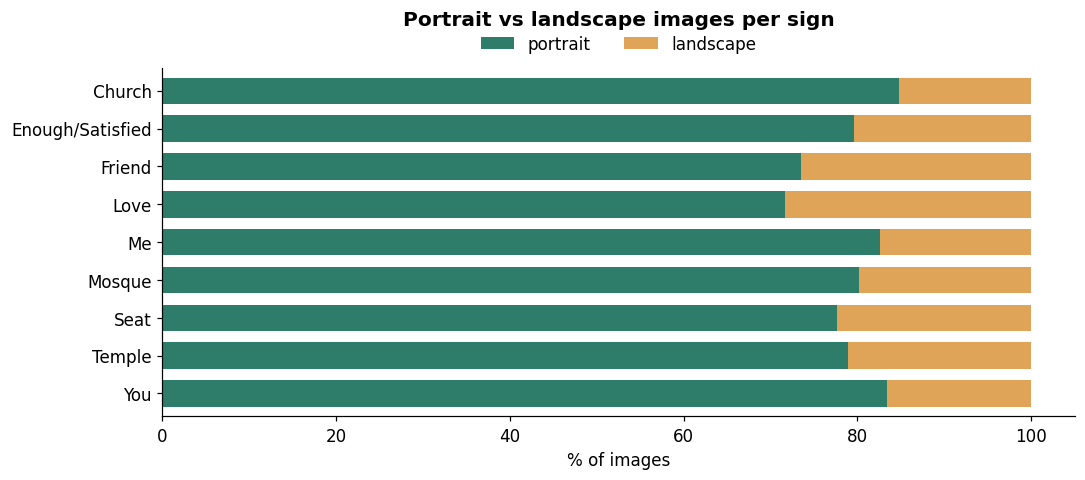

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/02_orientation_by_sign.csv
Result logged: landscape_share_overall_pct = 20.9
Result logged: landscape_share_range_pct = [15.3, 28.4]


orientation,landscape,portrait,landscape_%
label,,,
Church,106,588,15.3
Enough/Satisfied,142,553,20.4
Friend,184,510,26.5
Love,197,497,28.4
Me,121,573,17.4
Mosque,138,557,19.9
Seat,155,540,22.3
Temple,146,548,21.0
You,115,579,16.6


In [6]:
df["orientation"] = np.where(df["height"] > df["width"], "portrait", "landscape")

orient = pd.crosstab(df["label"], df["orientation"])
orient["landscape_%"] = (100 * orient["landscape"] / orient.sum(axis=1)).round(1)
orient = orient.reindex(SIGNS)

# Stacked horizontal bar: share of portrait vs landscape for each sign
fig, ax = plt.subplots(figsize=(10, 4.5))
share = orient[["portrait", "landscape"]].div(orient[["portrait", "landscape"]].sum(axis=1), axis=0) * 100
share.plot(kind="barh", stacked=True, ax=ax, color=["#2E7D6B", "#E0A458"], width=0.7)
ax.set_xlabel("% of images")
ax.set_ylabel("")
ax.set_title("Portrait vs landscape images per sign")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
ax.set_title("Portrait vs landscape images per sign", pad=28)
ax.invert_yaxis()
fig.tight_layout()
ku.save_figure(fig, "02_orientation_by_sign", NOTEBOOK, caption="Share of portrait and landscape images for each sign.")
plt.show()

ku.save_table(orient.reset_index(names="sign"), "02_orientation_by_sign", NOTEBOOK,
              caption="Portrait and landscape image counts per sign.")
ku.log_result("landscape_share_overall_pct", round(100 * (df["orientation"] == "landscape").mean(), 1), NOTEBOOK)
ku.log_result("landscape_share_range_pct", [float(orient["landscape_%"].min()), float(orient["landscape_%"].max())], NOTEBOOK)
orient

**Interpretation:** overall **20.9%** of images are landscape, but the share varies by sign from **15.3% (Church)** to **28.4% (Love)**. Orientation is therefore weakly linked to the label, which is a small shortcut a model could exploit. Stretching or padding would both preserve this cue (stretched proportions, or padding bars on different sides), so in preprocessing every image will be **centre-cropped to a square**. The average images in Section 6 show the hands sit in the centre of the frame, so a centre crop keeps the sign while removing the orientation cue.

## 3 · Variety within each sign
Five random examples per sign show how much the same sign varies between signers, backgrounds and lighting. This is the main reason deep learning is needed: the model has to recognise the **hand shape** despite everything else changing.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/02_examples_per_sign.png


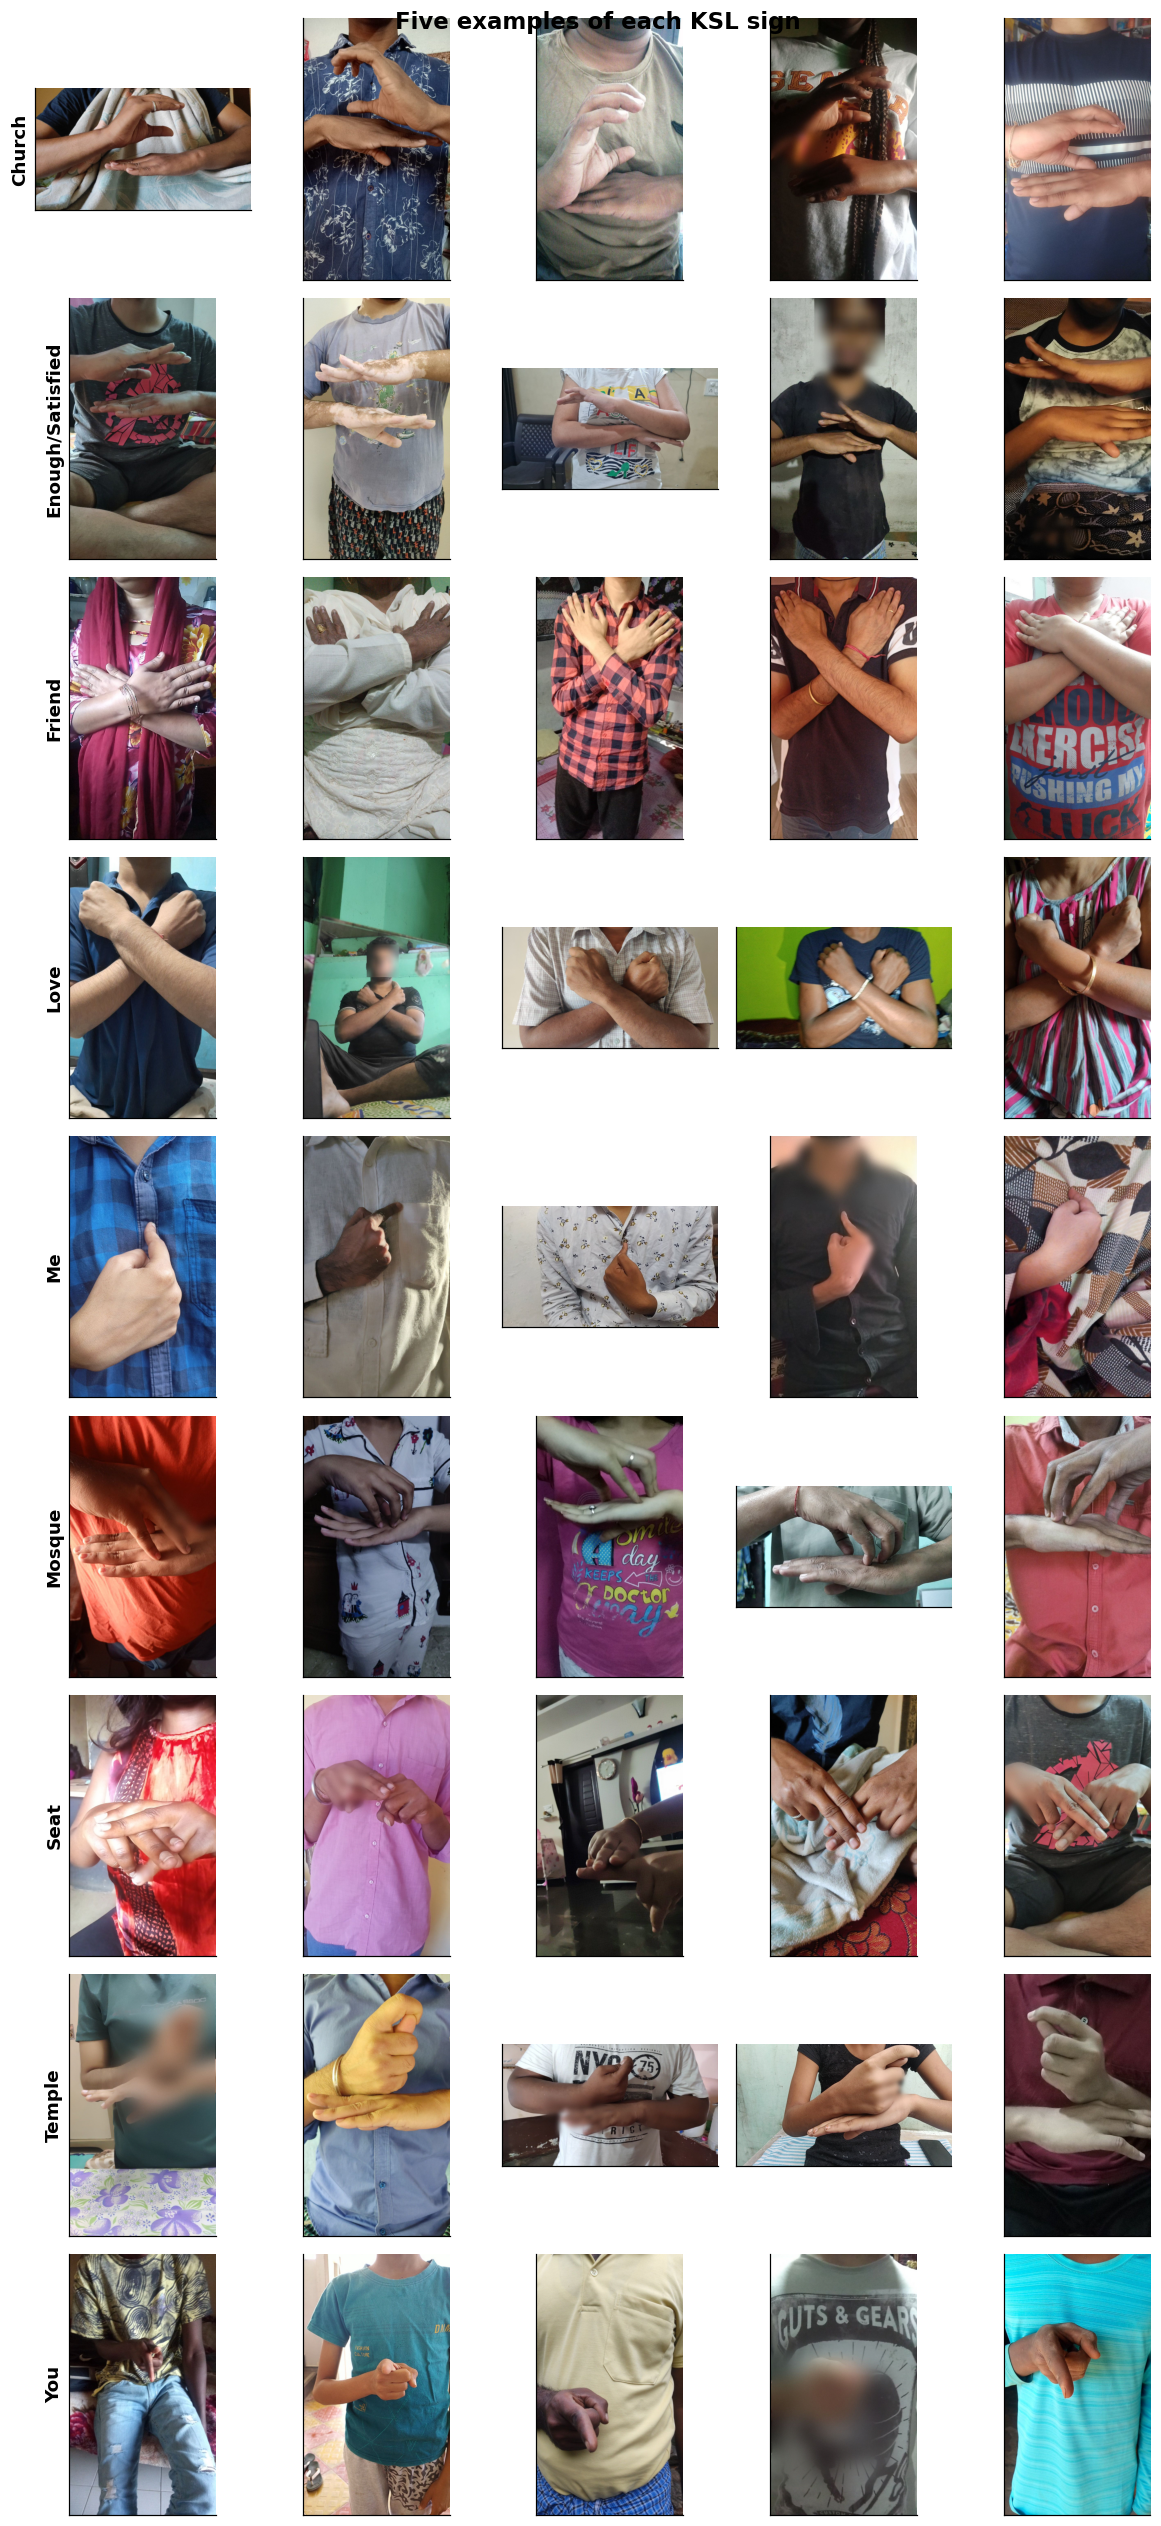

In [7]:
N_EXAMPLES = 5
fig, axes = plt.subplots(len(SIGNS), N_EXAMPLES, figsize=(2.2 * N_EXAMPLES, 2.6 * len(SIGNS)))

for r, sign in enumerate(SIGNS):
    sample = df[df["label"] == sign].sample(N_EXAMPLES, random_state=ku.SEED)
    for c, (_, row) in enumerate(sample.iterrows()):
        ax = axes[r, c]
        with Image.open(row["abs_path"]) as img:
            img.draft("RGB", (300, 300))              # fast reduced-size JPEG decode
            ax.imshow(img.convert("RGB"))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(sign, fontsize=12, fontweight="bold")

fig.suptitle("Five examples of each KSL sign", fontsize=15, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "02_examples_per_sign", NOTEBOOK, caption="Five random examples of each KSL sign.")
plt.show()

**Interpretation:** almost every photo is framed on the **signer's torso**, with faces cropped out or blurred for privacy. The hand shape is consistent within each sign, while clothing (often busy patterns), skin tone, background and lighting change completely between signers. Some images have a **blurred patch over the hands** (e.g. *Temple*, *You*), probably from privacy editing or motion, which will make those images harder to classify. Recognising the sign therefore requires learning hand and arm shape independently of everything around it, which is the core argument for deep learning.

## 4 · Image quality: brightness, contrast and sharpness
Three simple measures are computed for every image (on a reduced 320-pixel copy for speed):

| Measure | How it is computed | What it tells us |
|---|---|---|
| **Brightness** | Mean grey level (0 = black, 255 = white) | Under- or over-exposed photos |
| **Contrast** | Standard deviation of grey levels | Flat, washed-out photos |
| **Sharpness** | Variance of the Laplacian (an edge detector) | Low values = **blurry** (e.g. motion blur) |

This takes about 2–3 minutes for 6,249 images.

In [8]:
def quality_metrics(path: str) -> dict:
    """Brightness, contrast and sharpness of one image, measured on a 320-px greyscale copy."""
    with Image.open(path) as img:
        img.draft("L", (320, 320))                     # fast reduced-size decode
        grey = np.asarray(img.convert("L").resize((180, 320) if img.height > img.width else (320, 180)))
    return {"brightness": float(grey.mean()),
            "contrast": float(grey.std()),
            "sharpness": float(cv2.Laplacian(grey, cv2.CV_64F).var())}

quality = pd.DataFrame([quality_metrics(p) for p in tqdm(df["abs_path"], desc="Measuring quality")])
df[["brightness", "contrast", "sharpness"]] = quality

quality_summary = df[["brightness", "contrast", "sharpness"]].describe().T.round(1)
ku.save_table(quality_summary.reset_index(names="measure"), "02_quality_summary", NOTEBOOK,
              caption="Summary of brightness, contrast and sharpness across all images.")
quality_summary

Measuring quality:   0%|          | 0/6249 [00:00<?, ?it/s]

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/02_quality_summary.csv


,count,mean,std,min,25%,50%,75%,max
brightness,6249.0,107.7,23.1,49.4,90.8,107.4,123.6,194.6
contrast,6249.0,53.7,10.4,17.1,46.9,53.8,60.8,90.5
sharpness,6249.0,681.9,810.6,33.0,278.6,462.5,798.8,14164.6


Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/02_quality_by_sign.png


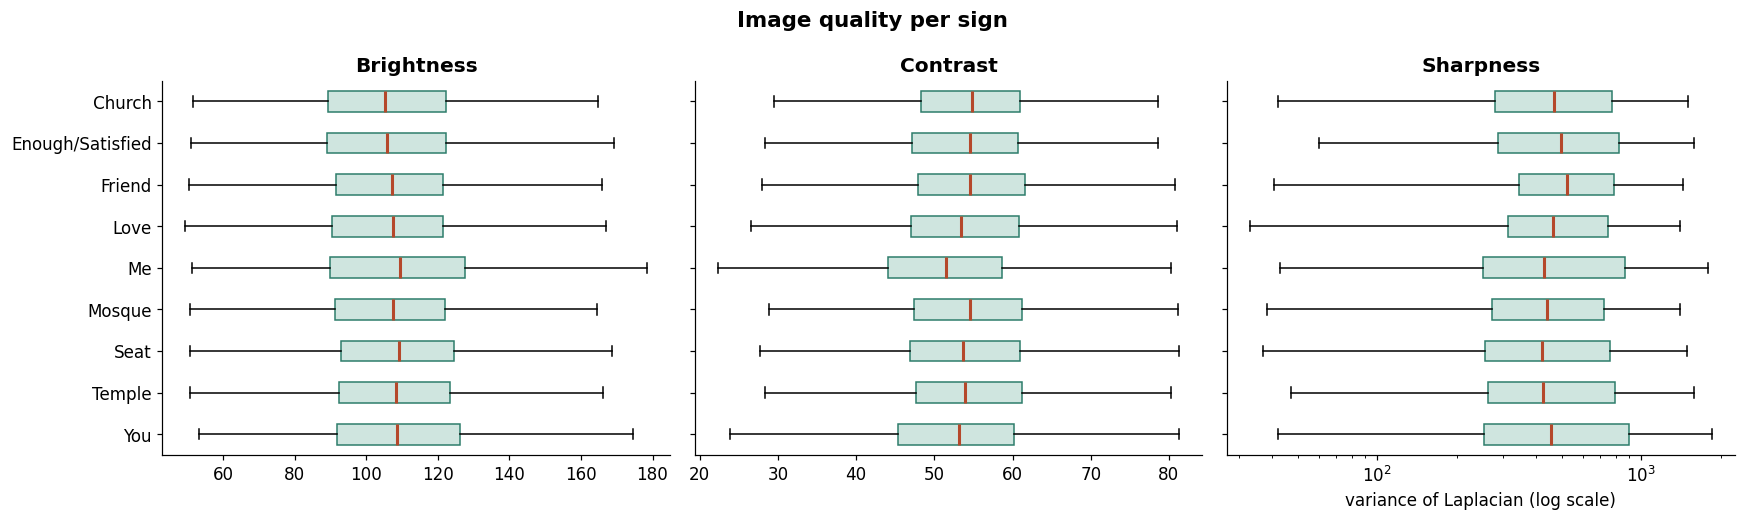

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/02_quality_by_sign.csv


,brightness,contrast,sharpness
label,,,
Church,105.3,54.8,468.6
Enough/Satisfied,105.7,54.6,496.1
Friend,107.1,54.5,525.3
Love,107.4,53.4,464.7
Me,109.3,51.5,428.9
Mosque,107.4,54.5,441.4
Seat,109.0,53.6,422.6
Temple,108.2,54.0,423.4
You,108.5,53.1,456.6


In [9]:
# Distribution of each quality measure per sign (box plots)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, metric in zip(axes, ["brightness", "contrast", "sharpness"]):
    data = [df.loc[df["label"] == s, metric] for s in SIGNS]
    style = dict(showfliers=False, patch_artist=True,
                 boxprops=dict(facecolor="#CFE5DF", color=SIGN_COLOUR),
                 medianprops=dict(color="#B5482B", linewidth=2))
    try:
        ax.boxplot(data, orientation="horizontal", **style)   # matplotlib >= 3.10
    except TypeError:
        ax.boxplot(data, vert=False, **style)                 # older matplotlib
    ax.set_yticks(range(1, len(SIGNS) + 1))
    ax.set_yticklabels(SIGNS)
    ax.set_title(metric.capitalize())
    if metric == "sharpness":
        ax.set_xscale("log")                            # sharpness varies over orders of magnitude
        ax.set_xlabel("variance of Laplacian (log scale)")
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("Image quality per sign", fontsize=14, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "02_quality_by_sign", NOTEBOOK, caption="Brightness, contrast and sharpness of images for each sign.")
plt.show()

# Per-sign medians, saved for the report
quality_by_sign = df.groupby("label")[["brightness", "contrast", "sharpness"]].median().round(1).reindex(SIGNS)
ku.save_table(quality_by_sign.reset_index(names="sign"), "02_quality_by_sign", NOTEBOOK,
              caption="Median brightness, contrast and sharpness per sign.")
quality_by_sign

### 4.1 · How many images are blurry?
There is no universal blur threshold, so we flag the **blurriest 5%** of images and look at them to judge whether they are still usable.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/02_blurriest_images.png


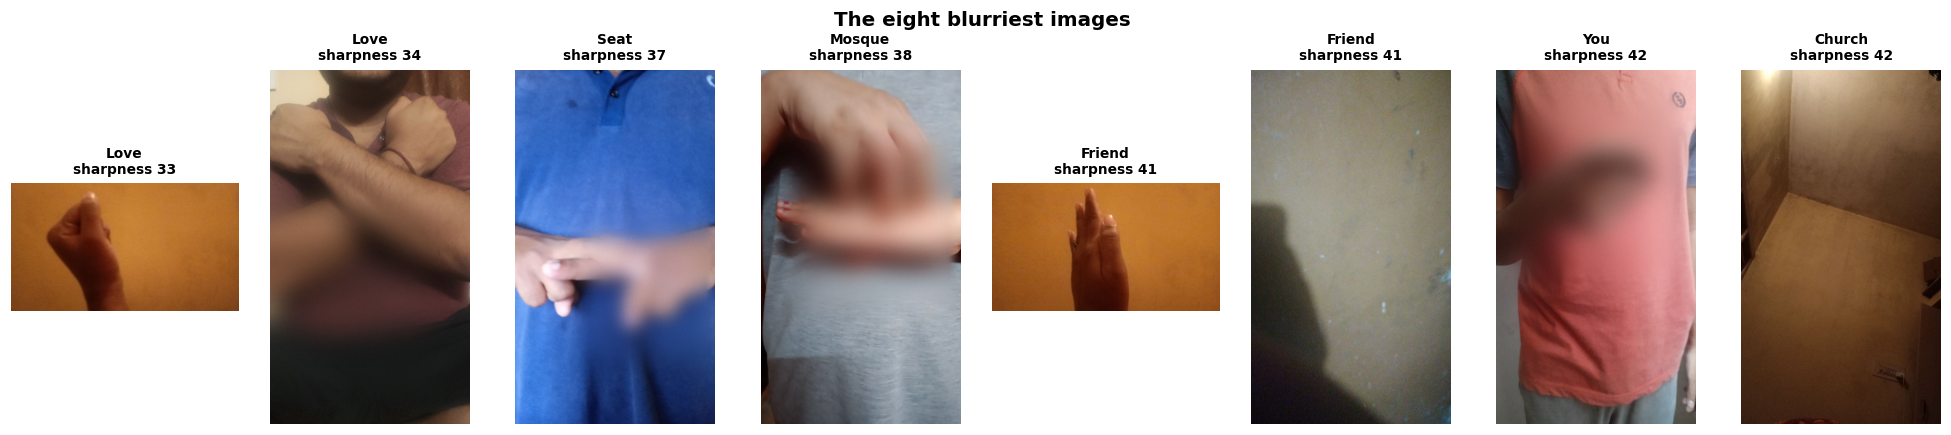

Result logged: blur_cutoff_sharpness_p5 = 126.7
Result logged: blurry_by_sign = {'Church': 32, 'Enough/Satisfied': 29, 'Friend': 20, 'Love': 34, 'Me': 48, 'Mosque': 26, 'Seat': 33, 'Temple': 36, 'You': 55}
Blurriest-5% images per sign:
 label
Church              32
Enough/Satisfied    29
Friend              20
Love                34
Me                  48
Mosque              26
Seat                33
Temple              36
You                 55


In [10]:
blur_cutoff = df["sharpness"].quantile(0.05)
df["is_blurry"] = df["sharpness"] < blur_cutoff

# Show the 8 blurriest images
blurriest = df.nsmallest(8, "sharpness")
fig, axes = plt.subplots(1, 8, figsize=(18, 4))
for ax, (_, row) in zip(axes, blurriest.iterrows()):
    with Image.open(row["abs_path"]) as img:
        img.draft("RGB", (300, 300))
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"{row['label']}\nsharpness {row['sharpness']:.0f}", fontsize=9)
    ax.axis("off")
fig.suptitle("The eight blurriest images", fontsize=13, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "02_blurriest_images", NOTEBOOK, caption="The eight images with the lowest sharpness score.")
plt.show()

blurry_by_sign = df.groupby("label")["is_blurry"].sum().reindex(SIGNS)
ku.log_result("blur_cutoff_sharpness_p5", round(float(blur_cutoff), 1), NOTEBOOK)
ku.log_result("blurry_by_sign", blurry_by_sign.astype(int).to_dict(), NOTEBOOK)
print("Blurriest-5% images per sign:\n", blurry_by_sign.to_string())

**Interpretation:** the blurriest 5% of images (sharpness below **126.7**) are spread over all signs but are most common in ***You* (55)** and ***Me* (48)**, both signs where the hand moves towards the body, so motion blur is likely. Most blurry images are still recognisable and are kept; blur augmentation during training will help the model cope with them. However, some of the blurriest images show **no hands at all** (an empty wall, an empty room), which suggests invalid or mislabelled photos. These are flagged for review and removal in preprocessing.

## 5 · Duplicate and near-duplicate images
Datasets collected with phones often contain **bursts**: several almost identical shots of the same person. If near-copies of one image land in both the training and test sets, the test score is inflated because the model has effectively seen the test image already (**data leakage**).

Two checks:
1. **Exact duplicates:** identical files (same MD5 checksum).
2. **Near-duplicates:** a *perceptual hash* (dHash) turns each image into a 64-bit fingerprint that stays almost the same if an image is slightly shifted, resized or re-compressed. Two images whose fingerprints differ in **≤ 6 of 64 bits** are treated as near-duplicates.

Near-duplicates are then linked into **groups**. Later, when splitting the data, every group goes entirely into train, validation **or** test, never across them.

In [11]:
def md5(path: str) -> str:
    """Checksum of the raw file bytes (identical files give identical checksums)."""
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


def dhash(path: str, size: int = 8) -> int:
    """Difference hash: 64-bit fingerprint comparing neighbouring pixel brightness."""
    with Image.open(path) as img:
        img.draft("L", (128, 128))
        small = np.asarray(img.convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()    # is each pixel brighter than its left neighbour?
    return int("".join("1" if b else "0" for b in bits), 2)


df["md5"] = [md5(p) for p in tqdm(df["abs_path"], desc="Checksums")]
df["dhash"] = [dhash(p) for p in tqdm(df["abs_path"], desc="Perceptual hashes")]

# 1. Exact duplicates
exact_dup_sets = df.groupby("md5").filter(lambda g: len(g) > 1)
n_exact_extra = int(len(exact_dup_sets) - exact_dup_sets["md5"].nunique())
print(f"Exact duplicate files (extra copies): {n_exact_extra}")

Checksums:   0%|          | 0/6249 [00:00<?, ?it/s]

Perceptual hashes:   0%|          | 0/6249 [00:00<?, ?it/s]

Exact duplicate files (extra copies): 0


In [12]:
# 2. Near-duplicates: compare every pair of fingerprints (≈19.5 million pairs, done in chunks)
HAMMING_THRESHOLD = 6
hashes = np.array(df["dhash"].tolist(), dtype=np.uint64)
n = len(hashes)

def popcount64(x: np.ndarray) -> np.ndarray:
    """Number of 1-bits in each 64-bit integer (= how many fingerprint bits differ)."""
    return np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1)

rows, cols = [], []
for i in tqdm(range(n - 1), desc="Comparing fingerprints"):
    dist = popcount64(np.bitwise_xor(hashes[i], hashes[i + 1:]))
    close = np.nonzero(dist <= HAMMING_THRESHOLD)[0] + i + 1
    rows.extend([i] * len(close))
    cols.extend(close.tolist())

# Link near-duplicate pairs into groups (connected components of a graph)
graph = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
n_groups, group_id = connected_components(graph, directed=False)
df["dup_group"] = group_id

group_sizes = df["dup_group"].map(df["dup_group"].value_counts())
n_in_groups = int((group_sizes > 1).sum())
print(f"Near-duplicate pairs found     : {len(rows)}")
print(f"Images with ≥1 near-duplicate  : {n_in_groups} ({100 * n_in_groups / n:.1f}%)")
print(f"Groups (incl. single images)   : {n_groups}")
print(f"Largest group size             : {group_sizes.max()}")

Comparing fingerprints:   0%|          | 0/6248 [00:00<?, ?it/s]

Near-duplicate pairs found     : 22
Images with ≥1 near-duplicate  : 25 (0.4%)
Groups (incl. single images)   : 6233
Largest group size             : 5


In [13]:
# Do any near-duplicate groups contain MORE than one label? (possible labelling errors)
labels_per_group = df.groupby("dup_group")["label"].nunique()
conflict_groups = labels_per_group[labels_per_group > 1].index
n_conflict_images = int(df["dup_group"].isin(conflict_groups).sum())

dup_summary = pd.DataFrame({
    "measure": ["Exact duplicate files (extra copies)", "Near-duplicate pairs",
                "Images with ≥1 near-duplicate", "Near-duplicate groups (size ≥ 2)",
                "Largest group", "Groups with conflicting labels", "Images in conflicting groups"],
    "value": [n_exact_extra, len(rows), n_in_groups, int((df["dup_group"].value_counts() > 1).sum()),
              int(group_sizes.max()), len(conflict_groups), n_conflict_images]})
ku.save_table(dup_summary, "02_duplicate_summary", NOTEBOOK, caption="Exact and near-duplicate image counts.")

ku.log_result("exact_duplicate_extra_copies", n_exact_extra, NOTEBOOK)
ku.log_result("near_dup_pairs", len(rows), NOTEBOOK)
ku.log_result("images_with_near_dup", n_in_groups, NOTEBOOK)
ku.log_result("images_with_near_dup_pct", round(100 * n_in_groups / n, 1), NOTEBOOK)
ku.log_result("near_dup_groups", int((df["dup_group"].value_counts() > 1).sum()), NOTEBOOK)
ku.log_result("dup_groups_conflicting_labels", len(conflict_groups), NOTEBOOK)
dup_summary

Table saved  -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/tables/02_duplicate_summary.csv
Result logged: exact_duplicate_extra_copies = 0
Result logged: near_dup_pairs = 22
Result logged: images_with_near_dup = 25
Result logged: images_with_near_dup_pct = 0.4
Result logged: near_dup_groups = 9
Result logged: dup_groups_conflicting_labels = 8


,measure,value
0,Exact duplicate files (extra copies),0
1,Near-duplicate pairs,22
2,Images with ≥1 near-duplicate,25
3,Near-duplicate groups (size ≥ 2),9
4,Largest group,5
5,Groups with conflicting labels,8
6,Images in conflicting groups,23


Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/02_near_duplicate_examples.png


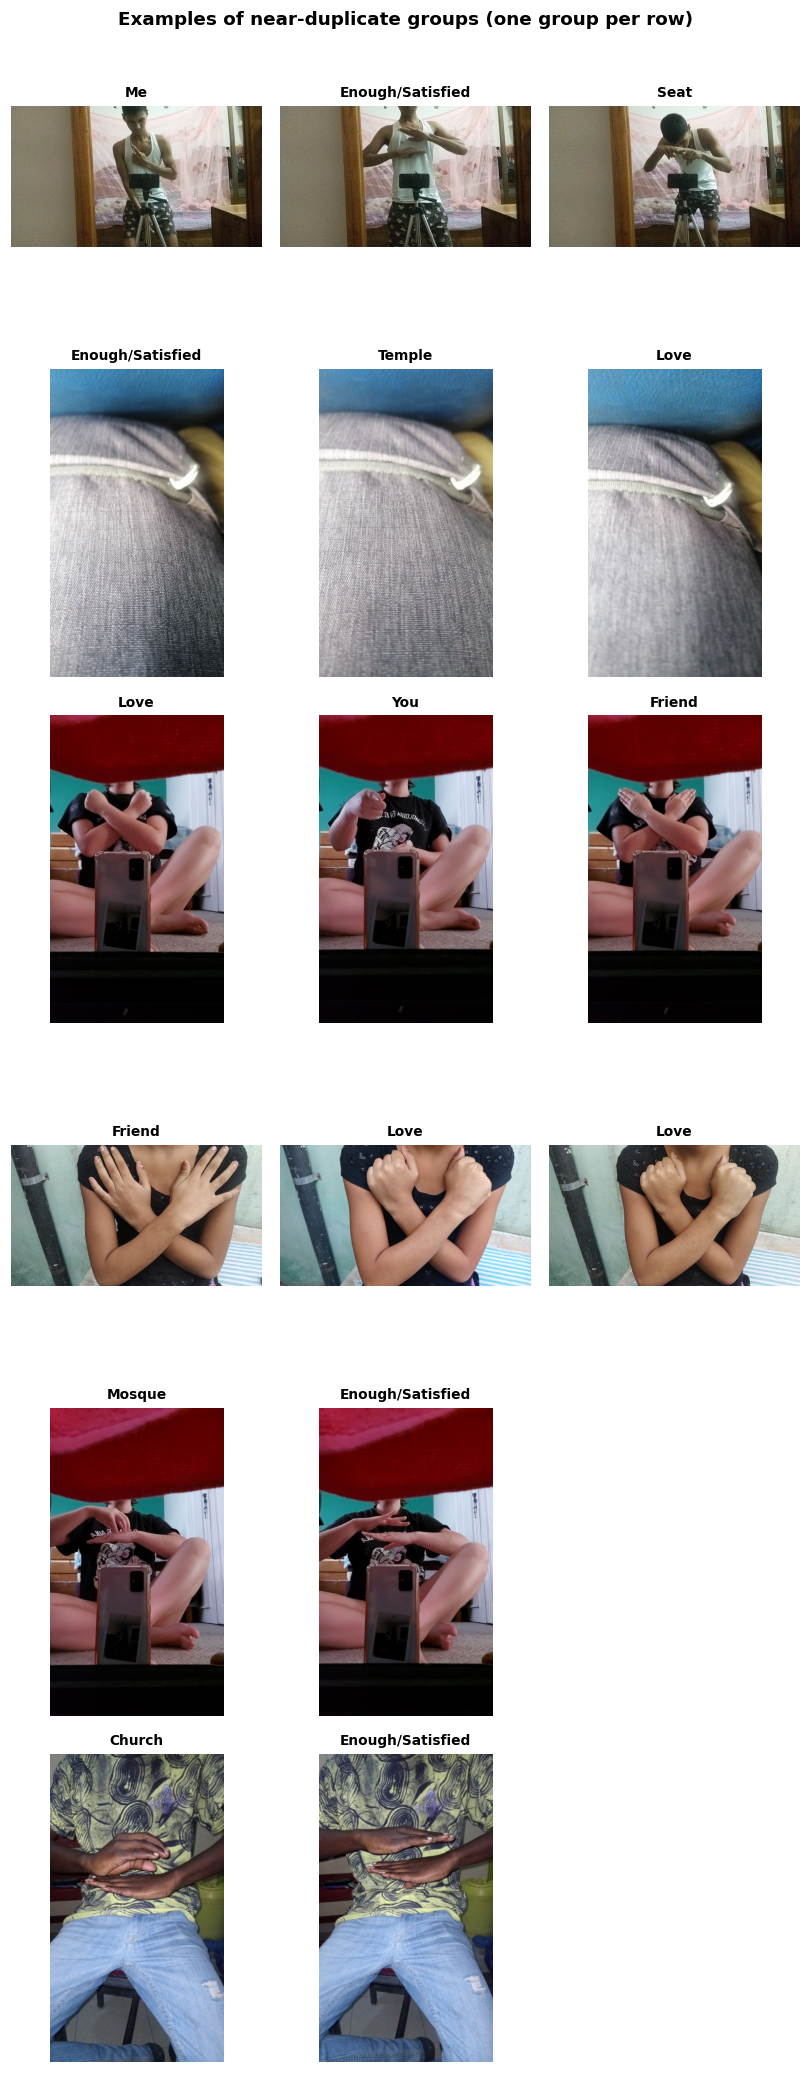

In [14]:
# Show up to 6 near-duplicate groups (3 images each) so we can judge them by eye
multi = df[group_sizes > 1]
show_groups = multi["dup_group"].value_counts().index[:6]
if len(show_groups):
    fig, axes = plt.subplots(len(show_groups), 3, figsize=(7.5, 3.2 * len(show_groups)), squeeze=False)
    for r, g in enumerate(show_groups):
        members = df[df["dup_group"] == g].head(3)
        for c in range(3):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(members):
                row = members.iloc[c]
                with Image.open(row["abs_path"]) as img:
                    img.draft("RGB", (300, 300))
                    ax.imshow(img.convert("RGB"))
                ax.set_title(f"{row['label']}", fontsize=9)
    fig.suptitle("Examples of near-duplicate groups (one group per row)", fontsize=12, fontweight="bold")
    fig.tight_layout()
    ku.save_figure(fig, "02_near_duplicate_examples", NOTEBOOK, caption="Examples of near-duplicate image groups.")
    plt.show()
else:
    print("No near-duplicate groups found.")

**Interpretation:** there are **no exact duplicate files**, and only **25 images (0.4%)** have a near-duplicate, forming **9 small groups** (largest 5). The risk of duplicate leakage is therefore negligible.

Surprisingly, **8 of the 9 groups mix different labels**. Inspecting them shows these are **not labelling errors**: they are the **same signer photographed in the same place** (same background, same tripod) performing different signs, and the fingerprint reacts to the shared background. Two findings follow:
1. **One group contains images with no sign at all** (a close-up of fabric) labelled as three different signs (*Enough/Satisfied*, *Temple*, *Love*). These are invalid and will be removed.
2. The same person appears under many signs. Signer IDs are not provided, so a **random split will put the same signers in both training and test sets**, which may make test accuracy optimistic. We keep each `dup_group` together when splitting, and state signer overlap as a limitation.

## 6 · The "average" image of each sign
Averaging every image of a sign (resized to the same size) blurs away backgrounds and people, leaving the parts that are **consistent across the sign**, usually the typical position of the hands and arms. It is a quick visual check that each class has a recognisable pattern, and it makes a striking presentation slide.

Figure saved -> /content/drive/MyDrive/DSA4050/ksl-recognition/outputs/figures/02_average_image_per_sign.png


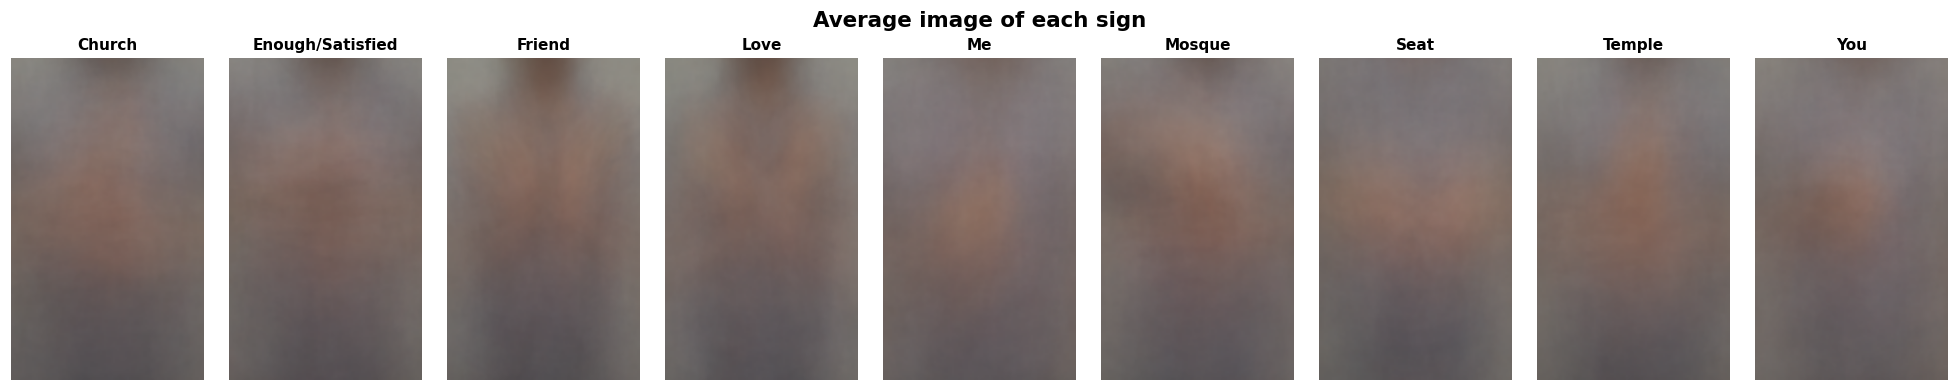

In [15]:
AVG_SIZE = (96, 160)   # width, height (portrait); landscape images are resized to fit too

fig, axes = plt.subplots(1, len(SIGNS), figsize=(2 * len(SIGNS), 3.6))
for ax, sign in zip(axes, SIGNS):
    total = np.zeros((AVG_SIZE[1], AVG_SIZE[0], 3), dtype=np.float64)
    paths = df.loc[df["label"] == sign, "abs_path"]
    for p in paths:
        with Image.open(p) as img:
            img.draft("RGB", (200, 200))
            total += np.asarray(img.convert("RGB").resize(AVG_SIZE), dtype=np.float64)
    ax.imshow((total / len(paths)).astype(np.uint8))
    ax.set_title(sign, fontsize=10)
    ax.axis("off")
fig.suptitle("Average image of each sign", fontsize=14, fontweight="bold")
fig.tight_layout()
ku.save_figure(fig, "02_average_image_per_sign", NOTEBOOK, caption="Pixel-wise average of all images for each sign.")
plt.show()

**Interpretation:** every average image is a **torso-centred blur with the hands in the middle**, and backgrounds average out to plain grey, so **no sign has a consistent background or colour** that a model could use as a shortcut. Faint sign-specific patterns are visible: *Love* and *Friend* show crossed arms forming an X on the upper chest, *Me* shows a single concentrated patch at mid-chest, and *Mosque* shows a diagonal arm from the upper left. Because the classes differ only in subtle hand and arm configurations, simple pixel-level methods are unlikely to separate them well, which supports the use of deep learning.

## 7 · Save the enriched catalogue
The catalogue now also holds orientation, quality measures and the near-duplicate group of every image. The modelling notebooks use `dup_group` for a leakage-free train/validation/test split.

In [16]:
keep = ["image_id", "label", "rel_path", "width", "height", "orientation",
        "brightness", "contrast", "sharpness", "is_blurry", "md5", "dhash", "dup_group"]
out = df[keep].copy()
out["dhash"] = out["dhash"].astype(str)          # store the 64-bit hash as text so it is not rounded
out.to_csv(os.path.join(PATHS["processed"], "catalogue_eda.csv"), index=False)
print("Saved:", os.path.join(PATHS["processed"], "catalogue_eda.csv"), out.shape)

Saved: /content/drive/MyDrive/DSA4050/ksl-recognition/data/processed/catalogue_eda.csv (6249, 13)


## Check · Project status

In [17]:
# Show what has been saved so far
ku.project_summary()

Project root : /content/drive/MyDrive/DSA4050/ksl-recognition
Figures      : 8
Tables       : 8
Models       : 0
Results      : 33
Experiments  : 0


## Findings for the report
- **Balance and baseline:** 9 signs × 694–695 images; a random guess scores **11.1%**, the baseline every model must beat.
- **Orientation:** 20.9% of images are landscape, ranging from 15.3% (*Church*) to 28.4% (*Love*). This weak orientation cue is removed by **centre-cropping all images to a square**.
- **Image quality:** median brightness 107 (range 49–195), contrast 54, sharpness 462, with **near-identical medians across signs**, so lighting and blur do not reveal the label. The blurriest 5% are concentrated in *You* (55) and *Me* (48), likely motion blur; blur augmentation will be used.
- **Invalid images:** a few photos contain **no visible sign** (fabric close-ups, empty walls or rooms); these are removed in preprocessing.
- **Duplicates and signers:** 0 exact duplicates and 25 near-duplicate images (0.4%) in 9 groups, so leakage from copies is negligible. The groups reveal that **the same signer appears in the same setting across several signs**; without signer IDs, signer overlap between train and test is a limitation.
- **Visual difficulty:** torso-framed photos with privacy-blurred faces; average images show only subtle differences between signs (*Love*/*Friend* crossed arms, *Me* single central hand), supporting a deep-learning approach.

**Next notebook:** `03_preprocessing.ipynb`: remove invalid images, centre-crop and resize, create the group-aware train/validation/test split, and prepare inputs for classic ML and deep learning.